In [12]:
import pandas as pd

inventory_df = pd.read_csv("inventory_df.csv")

print("Shape:", inventory_df.shape)

print("\nColumns:")
print(inventory_df.columns.tolist())

print("\nFirst 5 rows:")
display(inventory_df.head())

print("\nData types:")
print(inventory_df.dtypes)

print("\nMissing values:")
print(inventory_df.isnull().sum())

Shape: (60881, 14)

Columns:
['Unnamed: 0', 'product_id', 'category', 'supplier_id', 'order_year', 'order_month', 'historical_sales', 'avg_daily_sales', 'monthly_sales', 'current_stock', 'reorder_level', 'lead_time_days', 'reorder_quantity', 'warehouse_location']

First 5 rows:


,Unnamed: 0,product_id,category,supplier_id,order_year,order_month,historical_sales,avg_daily_sales,monthly_sales,current_stock,reorder_level,lead_time_days,reorder_quantity,warehouse_location
0,0,00066f42aeeb9f3007548bb9d3f33c38,perfumaria,48436dade18ac8b2bce089ec2a041202,2018,5,1,1.0,1,10,4,4,0,Hyderabad
1,1,00088930e925c41fd95ebfe695fd2655,artes,dd7ddc04e1b6c2c614352b383efe2d36,2017,12,1,1.0,1,10,3,2,0,Mumbai
2,2,0009406fd7479715e4bef61dd91f2462,esporte_lazer,5b51032eddd242adc84c38acab88f23d,2017,12,1,1.0,1,10,4,9,0,Indore
3,3,000b8f95fcb9e0096488278317764d19,bebes,9d7a1d34a5052409006425275ba1c2b4,2018,8,2,1.0,2,10,3,5,0,Bangalore
4,4,000d9be29b5207b54e86aa1b1ac54872,utilidades_domesticas,df560393f3a51e74553ab94004ba5c87,2018,4,1,1.0,1,10,3,3,0,Ahmedabad



Data types:
Unnamed: 0              int64
product_id                str
category                  str
supplier_id               str
order_year              int64
order_month             int64
historical_sales        int64
avg_daily_sales       float64
monthly_sales           int64
current_stock           int64
reorder_level           int64
lead_time_days          int64
reorder_quantity        int64
warehouse_location        str
dtype: object

Missing values:
Unnamed: 0            0
product_id            0
category              0
supplier_id           0
order_year            0
order_month           0
historical_sales      0
avg_daily_sales       0
monthly_sales         0
current_stock         0
reorder_level         0
lead_time_days        0
reorder_quantity      0
warehouse_location    0
dtype: int64


In [13]:
# Basic analysis of inventory-related variables

print("=== Statistical Summary ===")
display(
    inventory_df[
        [
            "historical_sales",
            "avg_daily_sales",
            "monthly_sales",
            "current_stock",
            "reorder_level",
            "lead_time_days",
            "reorder_quantity"
        ]
    ].describe()
)

print("\n=== Reorder Quantity Values ===")
print(inventory_df["reorder_quantity"].value_counts().sort_index())

print("\n=== Percentage of Zero Reorder Quantity ===")
zero_percentage = (
    (inventory_df["reorder_quantity"] == 0).mean() * 100
)
print(f"{zero_percentage:.2f}%")

print("\n=== Unique Values ===")
for column in [
    "historical_sales",
    "avg_daily_sales",
    "monthly_sales",
    "current_stock",
    "reorder_level",
    "lead_time_days",
    "reorder_quantity"
]:
    print(f"{column}: {inventory_df[column].nunique()} unique values")

=== Statistical Summary ===


,historical_sales,avg_daily_sales,monthly_sales,current_stock,reorder_level,lead_time_days,reorder_quantity
count,60881.000000,60881.000000,60881.000000,60881.000000,60881.000000,60881.000000,60881.0
mean,9.672098,1.137968,1.810039,11.488954,4.023603,6.099555,0.0
std,26.545727,0.397124,2.775562,10.233622,3.610161,2.510391,0.0
min,1.000000,1.000000,1.000000,10.000000,3.000000,2.000000,0.0
25%,1.000000,1.000000,1.000000,10.000000,3.000000,4.000000,0.0
50%,3.000000,1.000000,1.000000,10.000000,4.000000,6.000000,0.0
75%,8.000000,1.105263,2.000000,10.000000,4.000000,8.000000,0.0
max,520.000000,20.000000,121.000000,310.000000,108.000000,10.000000,0.0



=== Reorder Quantity Values ===
reorder_quantity
0    60881
Name: count, dtype: int64

=== Percentage of Zero Reorder Quantity ===
100.00%

=== Unique Values ===
historical_sales: 137 unique values
avg_daily_sales: 355 unique values
monthly_sales: 70 unique values
current_stock: 188 unique values
reorder_level: 88 unique values
lead_time_days: 9 unique values
reorder_quantity: 1 unique values


In [14]:
print("=== Correlation with Reorder Quantity ===")

correlation = inventory_df[
    [
        "historical_sales",
        "avg_daily_sales",
        "monthly_sales",
        "current_stock",
        "reorder_level",
        "lead_time_days",
        "reorder_quantity"
    ]
].corr()["reorder_quantity"].sort_values(ascending=False)

display(correlation)

=== Correlation with Reorder Quantity ===


historical_sales   NaN
avg_daily_sales    NaN
monthly_sales      NaN
current_stock      NaN
reorder_level      NaN
lead_time_days     NaN
reorder_quantity   NaN
Name: reorder_quantity, dtype: float64

In [15]:
# Check temporal structure of the inventory dataset

print("Number of unique products:")
print(inventory_df["product_id"].nunique())

print("\nNumber of unique suppliers:")
print(inventory_df["supplier_id"].nunique())

print("\nNumber of year-month combinations:")
print(
    inventory_df[["order_year", "order_month"]]
    .drop_duplicates()
    .shape[0]
)

print("\nRows per product - statistics:")
product_counts = inventory_df.groupby("product_id").size()

display(product_counts.describe())

print("\nProducts with more than one record:")
print((product_counts > 1).sum())

print("\nProducts with only one record:")
print((product_counts == 1).sum())

Number of unique products:
32216

Number of unique suppliers:
2698

Number of year-month combinations:
23

Rows per product - statistics:


count    32216.000000
mean         1.889775
std          1.800922
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         20.000000
dtype: float64


Products with more than one record:
11633

Products with only one record:
20583


In [16]:
import sys
print("Python path:", sys.executable)

import pandas as pd
print("Pandas version:", pd.__version__)


Python path: c:\Users\User\Desktop\Multi-Agent-Explainable-AI-Business-Intelligence-System-for-MSMEs\.venv\Scripts\python.exe
Pandas version: 3.0.6


In [17]:
# Check temporal structure of the inventory dataset

print("Number of unique products:")
print(inventory_df["product_id"].nunique())

print("\nNumber of unique suppliers:")
print(inventory_df["supplier_id"].nunique())

print("\nNumber of year-month combinations:")
print(
    inventory_df[["order_year", "order_month"]]
    .drop_duplicates()
    .shape[0]
)

print("\nRows per product - statistics:")
product_counts = inventory_df.groupby("product_id").size()

display(product_counts.describe())

print("\nProducts with more than one record:")
print((product_counts > 1).sum())

print("\nProducts with only one record:")
print((product_counts == 1).sum())

Number of unique products:
32216

Number of unique suppliers:
2698

Number of year-month combinations:
23

Rows per product - statistics:


count    32216.000000
mean         1.889775
std          1.800922
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         20.000000
dtype: float64


Products with more than one record:
11633

Products with only one record:
20583


In [1]:
import pandas as pd

inventory_df = pd.read_csv("inventory_df.csv")

print("Dataset loaded successfully!")
print("Shape:", inventory_df.shape)

Dataset loaded successfully!
Shape: (60881, 14)


In [19]:
import pandas as pd

inventory_df = pd.read_csv("inventory_df.csv")

print("Dataset loaded successfully!")
print("Shape:", inventory_df.shape)

Dataset loaded successfully!
Shape: (60881, 14)


In [20]:
print("Number of unique products:")
print(inventory_df["product_id"].nunique())

print("\nNumber of unique suppliers:")
print(inventory_df["supplier_id"].nunique())

print("\nNumber of year-month combinations:")
print(
    inventory_df[["order_year", "order_month"]]
    .drop_duplicates()
    .shape[0]
)

print("\nRows per product - statistics:")
product_counts = inventory_df.groupby("product_id").size()

display(product_counts.describe())

print("\nProducts with more than one record:")
print((product_counts > 1).sum())

print("\nProducts with only one record:")
print((product_counts == 1).sum())

Number of unique products:
32216

Number of unique suppliers:
2698

Number of year-month combinations:
23

Rows per product - statistics:


count    32216.000000
mean         1.889775
std          1.800922
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         20.000000
dtype: float64


Products with more than one record:
11633

Products with only one record:
20583


In [21]:
# Check unique months available for each product

product_month = (
    inventory_df[
        ["product_id", "order_year", "order_month"]
    ]
    .drop_duplicates()
)

months_per_product = product_month.groupby("product_id").size()

print("Unique product-month combinations:", len(product_month))

print("\nMonths available per product:")
display(months_per_product.describe())

print("\nNumber of products by number of months:")
display(months_per_product.value_counts().sort_index())

print("\nMaximum months available for one product:")
print(months_per_product.max())

Unique product-month combinations: 60881

Months available per product:


count    32216.000000
mean         1.889775
std          1.800922
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         20.000000
dtype: float64


Number of products by number of months:


1     20583
2      5582
3      2432
4      1247
5       803
6       485
7       328
8       246
9       151
10      111
11       73
12       64
13       44
14       23
15       14
16       12
17        7
18        5
19        4
20        2
Name: count, dtype: int64


Maximum months available for one product:
20


In [22]:
# Check duplicate records for the same product and month

duplicate_count = inventory_df.duplicated(
    subset=["product_id", "order_year", "order_month"]
).sum()

print("Duplicate product-year-month rows:", duplicate_count)

# Check which months exist in the dataset
available_months = (
    inventory_df[["order_year", "order_month"]]
    .drop_duplicates()
    .sort_values(["order_year", "order_month"])
)

display(available_months)

Duplicate product-year-month rows: 0


,order_year,order_month
21691,2016,9
564,2016,10
58393,2016,12
18,2017,1
11,2017,2
12,2017,3
21,2017,4
19,2017,5
20,2017,6
13,2017,7


In [2]:
# Prepare a valid next-month demand target

import pandas as pd

# Keep the original dataset unchanged
forecast_df = inventory_df.copy()

# Create a proper monthly date
forecast_df["period"] = pd.to_datetime(
    dict(
        year=forecast_df["order_year"],
        month=forecast_df["order_month"],
        day=1
    )
)

# Sort each product's records chronologically
forecast_df = forecast_df.sort_values(
    ["product_id", "period"]
).reset_index(drop=True)

# Find the next recorded month for the same product
forecast_df["next_period"] = (
    forecast_df.groupby("product_id")["period"].shift(-1)
)

# The prediction target is that product's next recorded monthly sales
forecast_df["target_next_month_sales"] = (
    forecast_df.groupby("product_id")["monthly_sales"].shift(-1)
)

# Calculate the calendar-month gap
current_month_index = (
    forecast_df["period"].dt.year * 12
    + forecast_df["period"].dt.month
)

next_month_index = (
    forecast_df["next_period"].dt.year * 12
    + forecast_df["next_period"].dt.month
)

forecast_df["month_gap"] = (
    next_month_index - current_month_index
)

# Keep only observations with a genuine following calendar month
forecast_data = forecast_df[
    forecast_df["month_gap"] == 1
].copy()

print("Original records:", len(inventory_df))
print("Valid consecutive-month pairs:", len(forecast_data))
print(
    "Products represented:",
    forecast_data["product_id"].nunique()
)

print("\nTarget summary:")
display(forecast_data["target_next_month_sales"].describe())

print("\nExample training rows:")
display(
    forecast_data[
        [
            "product_id",
            "period",
            "monthly_sales",
            "current_stock",
            "next_period",
            "target_next_month_sales"
        ]
    ].head(10)
)

Original records: 60881
Valid consecutive-month pairs: 16017
Products represented: 7015

Target summary:


count    16017.000000
mean         2.988575
std          4.827163
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max        121.000000
Name: target_next_month_sales, dtype: float64


Example training rows:


,product_id,period,monthly_sales,current_stock,next_period,target_next_month_sales
7,001795ec6f1b187d37335e1c4704762e,2017-10-01,1,10,2017-11-01,2.0
8,001795ec6f1b187d37335e1c4704762e,2017-11-01,2,10,2017-12-01,6.0
11,001b72dfd63e9833e8c02742adf472e3,2017-02-01,3,10,2017-03-01,1.0
13,001b72dfd63e9833e8c02742adf472e3,2017-07-01,3,10,2017-08-01,2.0
14,001b72dfd63e9833e8c02742adf472e3,2017-08-01,2,10,2017-09-01,2.0
16,001b72dfd63e9833e8c02742adf472e3,2017-11-01,1,10,2017-12-01,1.0
19,00210e41887c2a8ef9f791ebc780cc36,2017-05-01,1,10,2017-06-01,6.0
24,002159fe700ed3521f46cfcf6e941c76,2018-02-01,1,10,2018-03-01,1.0
25,002159fe700ed3521f46cfcf6e941c76,2018-03-01,1,10,2018-04-01,1.0
44,003128f981470c3e5a2e7445e4a771cd,2018-07-01,1,10,2018-08-01,1.0


In [3]:
print("Original dataset rows:", len(inventory_df))
print("Valid consecutive-month pairs:", len(forecast_data))
print("Unique products in forecast data:",
      forecast_data["product_id"].nunique())

print("\nTarget variable summary:")
display(
    forecast_data["target_next_month_sales"].describe()
)

print("\nMost common target values:")
display(
    forecast_data["target_next_month_sales"]
    .value_counts()
    .sort_index()
    .head(20)
)

Original dataset rows: 60881
Valid consecutive-month pairs: 16017
Unique products in forecast data: 7015

Target variable summary:


count    16017.000000
mean         2.988575
std          4.827163
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max        121.000000
Name: target_next_month_sales, dtype: float64


Most common target values:


target_next_month_sales
1.0     7783
2.0     3273
3.0     1608
4.0      922
5.0      574
6.0      418
7.0      277
8.0      201
9.0      160
10.0     141
11.0      88
12.0      77
13.0      71
14.0      49
15.0      46
16.0      38
17.0      39
18.0      26
19.0      28
20.0      15
Name: count, dtype: int64

In [4]:
# Baseline: predict the average next-month sales
y = forecast_data["target_next_month_sales"]

print("Baseline MAE:", (y - y.mean()).abs().mean())
print("Baseline RMSE:", ((y - y.mean()) ** 2).mean() ** 0.5)

Baseline MAE: 2.336602511545287
Baseline RMSE: 4.827012587383885


In [5]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Sort records by the month in which the forecast would be made
forecast_data = forecast_data.sort_values("period").copy()

# Hold out the final 5 distinct months for testing
available_periods = sorted(forecast_data["period"].unique())
test_periods = available_periods[-5:]

train_data = forecast_data[
    ~forecast_data["period"].isin(test_periods)
].copy()

test_data = forecast_data[
    forecast_data["period"].isin(test_periods)
].copy()

# Separate target from input data
y_train = train_data["target_next_month_sales"].astype(float)
y_test = test_data["target_next_month_sales"].astype(float)

print("Training records:", len(train_data))
print("Testing records:", len(test_data))

print("\nTraining period:")
print(train_data["period"].min(), "to", train_data["period"].max())

print("\nTesting period:")
print(test_data["period"].min(), "to", test_data["period"].max())

Training records: 10367
Testing records: 5650

Training period:
2016-09-01 00:00:00 to 2018-02-01 00:00:00

Testing period:
2018-03-01 00:00:00 to 2018-07-01 00:00:00


In [6]:
# Baseline 1: predict the average demand from the training set
mean_prediction = np.full(len(y_test), y_train.mean())

# Baseline 2: assume next month's sales equal this month's sales
current_month_prediction = test_data["monthly_sales"].astype(float)

def evaluate_predictions(y_true, predictions):
    mae = mean_absolute_error(y_true, predictions)
    rmse = np.sqrt(mean_squared_error(y_true, predictions))

    return {
        "MAE": round(mae, 4),
        "RMSE": round(rmse, 4)
    }

baseline_results = {
    "Training mean baseline": evaluate_predictions(
        y_test, mean_prediction
    ),
    "Previous month sales baseline": evaluate_predictions(
        y_test, current_month_prediction
    )
}

import pandas as pd
display(pd.DataFrame(baseline_results).T)

,MAE,RMSE
Training mean baseline,2.2950,4.6316
Previous month sales baseline,1.7219,4.0267


In [7]:
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Features available at the time of prediction
numeric_features = [
    "order_year",
    "order_month",
    "historical_sales",
    "avg_daily_sales",
    "monthly_sales",
    "current_stock",
    "reorder_level",
    "lead_time_days"
]

categorical_features = [
    "category",
    "warehouse_location"
]

feature_columns = numeric_features + categorical_features
target_column = "target_next_month_sales"

# Prepare train/test inputs
X_train = train_data[feature_columns].copy()
X_test = test_data[feature_columns].copy()

y_train = train_data[target_column].astype(float)
y_test = test_data[target_column].astype(float)

# Handle missing values and encode categories
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Number of input features:", len(feature_columns))

Training features: (10367, 10)
Testing features: (5650, 10)
Number of input features: 10


In [26]:
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=150,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=150,
        max_leaf_nodes=20,
        l2_regularization=1.0,
        random_state=42
    )
}

trained_models = {}
results = []

# Baseline 1: training-set mean
mean_predictions = np.full(len(y_test), y_train.mean())

results.append({
    "Model": "Training mean baseline",
    "MAE": mean_absolute_error(y_test, mean_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, mean_predictions))
})

# Baseline 2: previous month's sales
previous_sales_predictions = test_data["monthly_sales"].astype(float)

results.append({
    "Model": "Previous month baseline",
    "MAE": mean_absolute_error(y_test, previous_sales_predictions),
    "RMSE": np.sqrt(
        mean_squared_error(y_test, previous_sales_predictions)
    )
})

# Train and evaluate each ML model
for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    print(f"Training {name}...")

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    # Demand cannot be negative
    predictions = np.maximum(predictions, 0)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

    trained_models[name] = pipeline

# Compare results
results_df = (
    pd.DataFrame(results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(results_df.round(4))

Training Random Forest...
Training Extra Trees...
Training HistGradientBoosting...


,Model,MAE,RMSE
0,HistGradientBoosting,1.6235,3.4548
1,Random Forest,1.6625,3.4674
2,Extra Trees,1.6963,3.5915
3,Previous month baseline,1.7219,4.0267
4,Training mean baseline,2.2950,4.6316


In [9]:
from pathlib import Path
import joblib

# Create the required folders
models_dir = Path("models")
shap_dir = models_dir / "shap"

models_dir.mkdir(parents=True, exist_ok=True)
shap_dir.mkdir(parents=True, exist_ok=True)

# Select Random Forest based on lowest MAE
best_model_name = "Random Forest"
best_model = trained_models[best_model_name]

# Save the complete pipeline, including preprocessing
joblib.dump(
    best_model,
    models_dir / "inventory_product_demand_model.pkl"
)

# Save the original input feature names
joblib.dump(
    feature_columns,
    models_dir / "inventory_features.pkl"
)

# Save comparison results
results_df.to_csv(
    models_dir / "model_evaluation.csv",
    index=False
)

print("Selected model:", best_model_name)
print("Model and feature list saved successfully.")
print("Evaluation results saved successfully.")
print("Files saved in:", models_dir.resolve())

FileExistsError: [WinError 183] Cannot create a file when that file already exists: 'models\\shap'

In [10]:
from pathlib import Path

p = Path("models/shap")

print("Current working directory:", Path.cwd())
print("Path:", p.resolve())
print("Exists:", p.exists())
print("Is directory:", p.is_dir())
print("Is file:", p.is_file())

print("\nItems inside models:")
for item in Path("models").iterdir():
    print(item.name, "| Directory:", item.is_dir(), "| File:", item.is_file())

Current working directory: c:\Users\User\Desktop\Multi-Agent-Explainable-AI-Business-Intelligence-System-for-MSMEs\AI Agents\inventory
Path: C:\Users\User\Desktop\Multi-Agent-Explainable-AI-Business-Intelligence-System-for-MSMEs\AI Agents\inventory\models\shap
Exists: True
Is directory: False
Is file: True

Items inside models:
shap | Directory: False | File: True


In [11]:
from pathlib import Path

models_dir = Path("models")
shap_path = models_dir / "shap"

# Preserve the existing file by renaming it
if shap_path.is_file():
    backup_path = models_dir / "shap_backup"

    if backup_path.exists():
        backup_path = models_dir / "shap_backup_1"

    shap_path.rename(backup_path)
    print(f"Existing file preserved as: {backup_path}")

# Create the required SHAP folder
shap_path.mkdir(parents=True, exist_ok=True)

print("SHAP folder created:", shap_path.is_dir())
print("Folder path:", shap_path.resolve())

Existing file preserved as: models\shap_backup
SHAP folder created: True
Folder path: C:\Users\User\Desktop\Multi-Agent-Explainable-AI-Business-Intelligence-System-for-MSMEs\AI Agents\inventory\models\shap


In [12]:
from pathlib import Path
import joblib

# Create the required folders
models_dir = Path("models")
shap_dir = models_dir / "shap"

models_dir.mkdir(parents=True, exist_ok=True)
shap_dir.mkdir(parents=True, exist_ok=True)

# Select Random Forest based on lowest MAE
best_model_name = "Random Forest"
best_model = trained_models[best_model_name]

# Save the complete pipeline, including preprocessing
joblib.dump(
    best_model,
    models_dir / "inventory_product_demand_model.pkl"
)

# Save the original input feature names
joblib.dump(
    feature_columns,
    models_dir / "inventory_features.pkl"
)

# Save comparison results
results_df.to_csv(
    models_dir / "model_evaluation.csv",
    index=False
)

print("Selected model:", best_model_name)
print("Model and feature list saved successfully.")
print("Evaluation results saved successfully.")
print("Files saved in:", models_dir.resolve())

Selected model: Random Forest
Model and feature list saved successfully.
Evaluation results saved successfully.
Files saved in: C:\Users\User\Desktop\Multi-Agent-Explainable-AI-Business-Intelligence-System-for-MSMEs\AI Agents\inventory\models


In [13]:
import shap
import matplotlib.pyplot as plt
import numpy as np

# Extract the trained model and preprocessing pipeline
preprocessor = best_model.named_steps["preprocessor"]
rf_model = best_model.named_steps["model"]

# Use a manageable sample from the test set
X_shap_raw = X_test.sample(
    n=min(300, len(X_test)),
    random_state=42
)

X_shap_transformed = preprocessor.transform(X_shap_raw)

transformed_feature_names = (
    preprocessor.get_feature_names_out()
)

# Calculate SHAP values
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_shap_transformed)

# SHAP summary plot
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=transformed_feature_names,
    max_display=20,
    show=False
)

plt.tight_layout()
plt.savefig(
    shap_dir / "shap_summary.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close()

# SHAP feature importance bar plot
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=transformed_feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.tight_layout()
plt.savefig(
    shap_dir / "shap_feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("SHAP plots saved in:", shap_dir.resolve())

ModuleNotFoundError: No module named 'shap'

In [16]:
import shap
import matplotlib.pyplot as plt
from pathlib import Path

# Get the selected Random Forest model
preprocessor = best_model.named_steps["preprocessor"]
rf_model = best_model.named_steps["model"]

# Select a small test sample
X_shap_raw = X_test.sample(
    n=min(300, len(X_test)),
    random_state=42
)

# Apply the training-time preprocessing
X_shap_transformed = preprocessor.transform(X_shap_raw)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Calculate SHAP values
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_shap_transformed)

# Create output directory
shap_dir = Path("models") / "shap"
shap_dir.mkdir(parents=True, exist_ok=True)

# 1. SHAP summary plot
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.savefig(
    shap_dir / "shap_summary.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 2. SHAP feature importance plot
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.savefig(
    shap_dir / "shap_feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("SHAP plots saved successfully.")
print("Saved to:", shap_dir.resolve())

ModuleNotFoundError: No module named 'shap'

In [17]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ------------- -------------------------- 262.1/751.9 kB ? eta -:--:--
   -------------------------- ----------- 524.3/751.9 kB 911.7 kB/s eta 0:00:01
   -------------------------- ----------- 524.3/751.9 kB 911.7 kB/s eta 0:00:01
   -------------------------------------- 751.9/751.9 kB 802.4 kB/s eta 0:00:00

   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ------------- -------------------------- 1/3 [slicer]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3


[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
import sys
import shap

print("Python environment:", sys.executable)
print("SHAP version:", shap.__version__)

c:\Users\User\Desktop\Multi-Agent-Explainable-AI-Business-Intelligence-System-for-MSMEs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python environment: c:\Users\User\Desktop\Multi-Agent-Explainable-AI-Business-Intelligence-System-for-MSMEs\.venv\Scripts\python.exe
SHAP version: 0.54.1


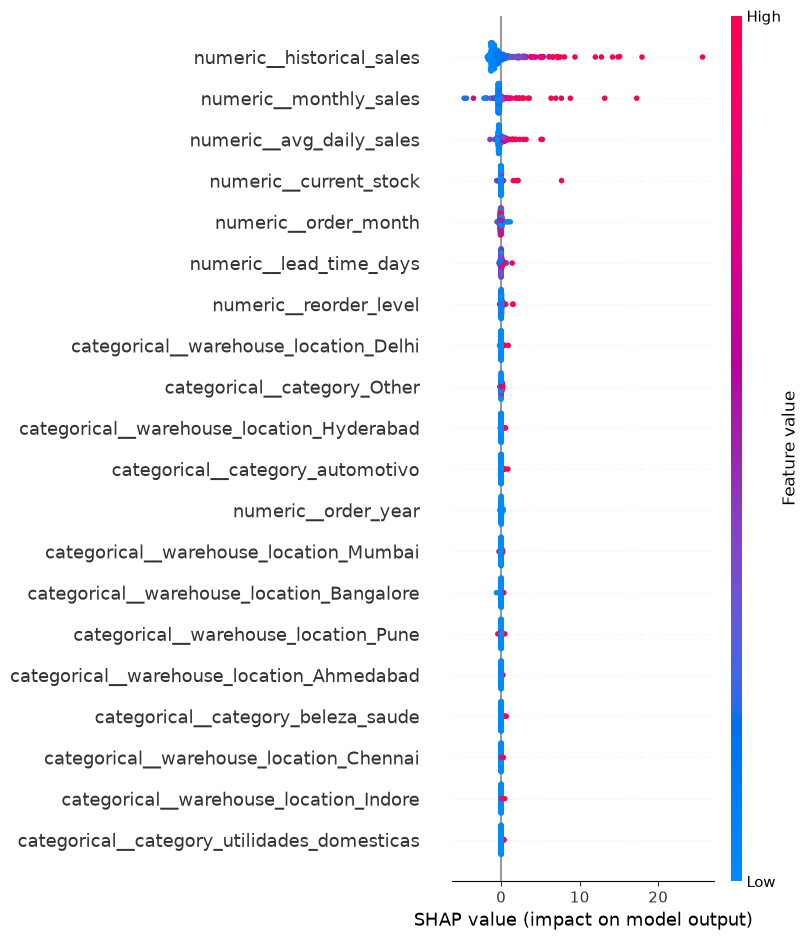

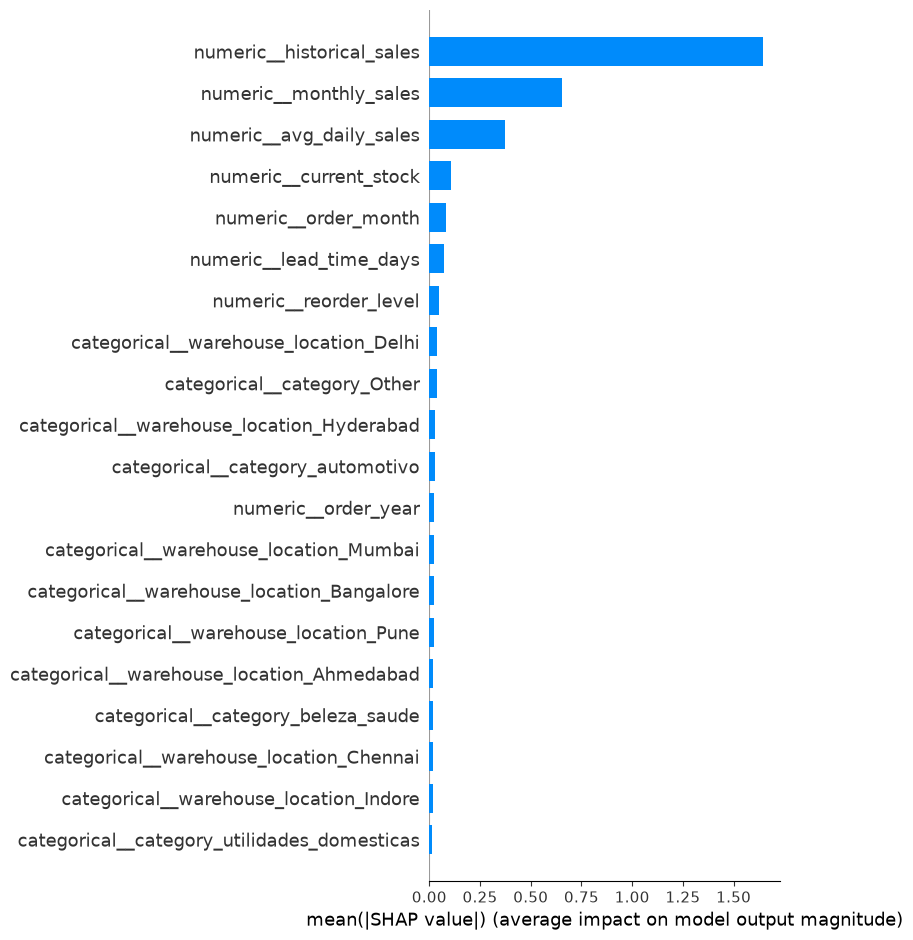

SHAP plots saved successfully.
Saved to: C:\Users\User\Desktop\Multi-Agent-Explainable-AI-Business-Intelligence-System-for-MSMEs\AI Agents\inventory\models\shap


In [19]:
import shap
import matplotlib.pyplot as plt
from pathlib import Path

# Get the selected Random Forest model
preprocessor = best_model.named_steps["preprocessor"]
rf_model = best_model.named_steps["model"]

# Select a small test sample
X_shap_raw = X_test.sample(
    n=min(300, len(X_test)),
    random_state=42
)

# Apply the training-time preprocessing
X_shap_transformed = preprocessor.transform(X_shap_raw)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Calculate SHAP values
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_shap_transformed)

# Create output directory
shap_dir = Path("models") / "shap"
shap_dir.mkdir(parents=True, exist_ok=True)

# 1. SHAP summary plot
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.savefig(
    shap_dir / "shap_summary.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 2. SHAP feature importance plot
shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.savefig(
    shap_dir / "shap_feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("SHAP plots saved successfully.")
print("Saved to:", shap_dir.resolve())

In [20]:
from inventory_agent import inventory_agent

sample_inventory = {
    "order_year": 2018,
    "order_month": 5,
    "historical_sales": 1,
    "avg_daily_sales": 1.0,
    "monthly_sales": 1,
    "current_stock": 10,
    "reorder_level": 4,
    "lead_time_days": 4,
    "category": "perfumaria",
    "warehouse_location": "Hyderabad"
}

result = inventory_agent(sample_inventory)

print("Inventory Agent Output:")
print(result)

Inventory Agent Output:
{'agent': 'inventory', 'prediction': {'predicted_next_month_demand': 1.0, 'current_stock': 10.0, 'stock_risk': 'Low', 'reorder_required': False, 'recommended_reorder_quantity': 0, 'estimated_lead_time_demand': 0.13}, 'explanation': 'Predicted demand for the next month is 1.00 units. Current stock is 10 units, and the reorder-level buffer is 4 units. Estimated demand during the 4-day supplier lead time is 0.13 units.', 'recommended_action': 'Current stock covers the estimated demand and reorder buffer. Continue monitoring sales and inventory levels.'}


In [21]:
from inventory_agent import inventory_agent

# Test the same product information with different stock levels
for stock in [1, 10, 100]:
    test_input = sample_inventory.copy()
    test_input["current_stock"] = stock

    result = inventory_agent(test_input)

    print(f"\n{'=' * 40}")
    print(f"Current stock: {stock}")
    print("Prediction:", result["prediction"])
    print("Recommendation:", result["recommended_action"])


Current stock: 1
Prediction: {'predicted_next_month_demand': 1.0, 'current_stock': 1.0, 'stock_risk': 'High', 'reorder_required': True, 'recommended_reorder_quantity': 4, 'estimated_lead_time_demand': 0.13}
Recommendation: High stock risk. Prioritize replenishment of approximately 4 units to meet the estimated demand and reorder buffer.

Current stock: 10
Prediction: {'predicted_next_month_demand': 1.0, 'current_stock': 10.0, 'stock_risk': 'Low', 'reorder_required': False, 'recommended_reorder_quantity': 0, 'estimated_lead_time_demand': 0.13}
Recommendation: Current stock covers the estimated demand and reorder buffer. Continue monitoring sales and inventory levels.

Current stock: 100
Prediction: {'predicted_next_month_demand': 2.67, 'current_stock': 100.0, 'stock_risk': 'Low', 'reorder_required': False, 'recommended_reorder_quantity': 0, 'estimated_lead_time_demand': 0.34}
Recommendation: Current stock covers the estimated demand and reorder buffer. Continue monitoring sales and inv

In [22]:
# Check whether historical_sales varies across records for each product

historical_variation = (
    inventory_df.groupby("product_id")["historical_sales"]
    .nunique()
)

print(
    "Products where historical_sales varies:",
    (historical_variation > 1).sum()
)

print(
    "Products where historical_sales is constant:",
    (historical_variation == 1).sum()
)

print("\nExample: records for a product appearing multiple times")

example_product = (
    inventory_df["product_id"]
    .value_counts()
    .loc[lambda counts: counts > 1]
    .index[0]
)

display(
    inventory_df.loc[
        inventory_df["product_id"] == example_product,
        [
            "product_id",
            "order_year",
            "order_month",
            "historical_sales",
            "monthly_sales",
            "avg_daily_sales"
        ]
    ].sort_values(["order_year", "order_month"])
)

Products where historical_sales varies: 0
Products where historical_sales is constant: 32216

Example: records for a product appearing multiple times


,product_id,order_year,order_month,historical_sales,monthly_sales,avg_daily_sales
25944,6cdd53843498f92890544667809f1595,2017,1,153,8,1.330435
25945,6cdd53843498f92890544667809f1595,2017,2,153,4,1.330435
25946,6cdd53843498f92890544667809f1595,2017,3,153,2,1.330435
25947,6cdd53843498f92890544667809f1595,2017,4,153,1,1.330435
25948,6cdd53843498f92890544667809f1595,2017,5,153,4,1.330435
25949,6cdd53843498f92890544667809f1595,2017,6,153,2,1.330435
25950,6cdd53843498f92890544667809f1595,2017,7,153,1,1.330435
25951,6cdd53843498f92890544667809f1595,2017,8,153,7,1.330435
25952,6cdd53843498f92890544667809f1595,2017,9,153,7,1.330435
25953,6cdd53843498f92890544667809f1595,2017,10,153,10,1.330435


In [23]:
# Remove potentially future-derived aggregate features
# from the forecasting model.

numeric_features = [
    "order_year",
    "order_month",
    "monthly_sales",
    "current_stock",
    "reorder_level",
    "lead_time_days"
]

categorical_features = [
    "category",
    "warehouse_location"
]

feature_columns = numeric_features + categorical_features
target_column = "target_next_month_sales"

X_train = train_data[feature_columns].copy()
X_test = test_data[feature_columns].copy()

y_train = train_data[target_column].astype(float)
y_test = test_data[target_column].astype(float)

print("Updated features:")
print(feature_columns)

print("\nTraining shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Updated features:
['order_year', 'order_month', 'monthly_sales', 'current_stock', 'reorder_level', 'lead_time_days', 'category', 'warehouse_location']

Training shape: (10367, 8)
Testing shape: (5650, 8)


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Preprocessing for numeric features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Rebuild using the UPDATED feature lists
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessor updated successfully.")
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Preprocessor updated successfully.
Numeric features: ['order_year', 'order_month', 'monthly_sales', 'current_stock', 'reorder_level', 'lead_time_days']
Categorical features: ['category', 'warehouse_location']


In [27]:
from pathlib import Path
import joblib

models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

# Select the best model using the updated results
best_model_name = "HistGradientBoosting"
best_model = trained_models[best_model_name]

# Save the complete preprocessing + model pipeline
joblib.dump(
    best_model,
    models_dir / "inventory_product_demand_model.pkl"
)

# Save the current feature list
joblib.dump(
    feature_columns,
    models_dir / "inventory_features.pkl"
)

# Save all model comparison results
results_df.to_csv(
    models_dir / "model_evaluation.csv",
    index=False
)

print("Selected model:", best_model_name)
print("Model saved successfully.")
print("Features saved:", feature_columns)
print("Evaluation saved successfully.")

Selected model: HistGradientBoosting
Model saved successfully.
Features saved: ['order_year', 'order_month', 'monthly_sales', 'current_stock', 'reorder_level', 'lead_time_days', 'category', 'warehouse_location']
Evaluation saved successfully.


C:\Users\User\AppData\Local\Temp\ipykernel_12444\3920239505.py:43: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


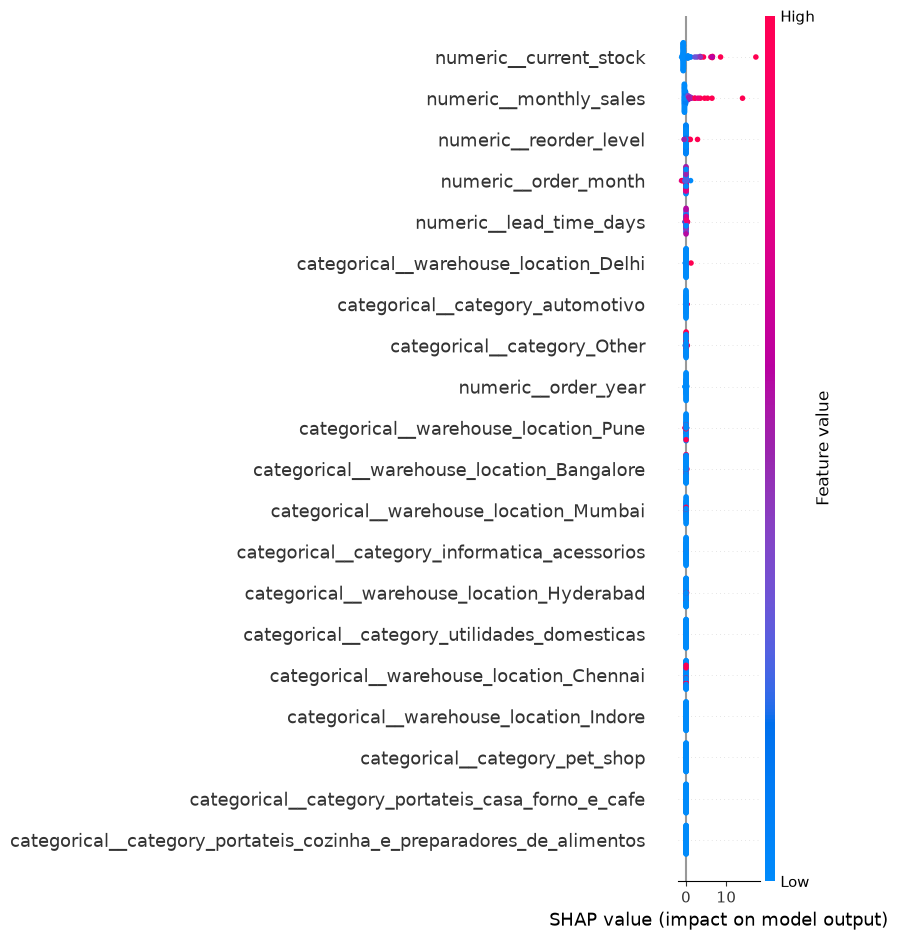

C:\Users\User\AppData\Local\Temp\ipykernel_12444\3920239505.py:60: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


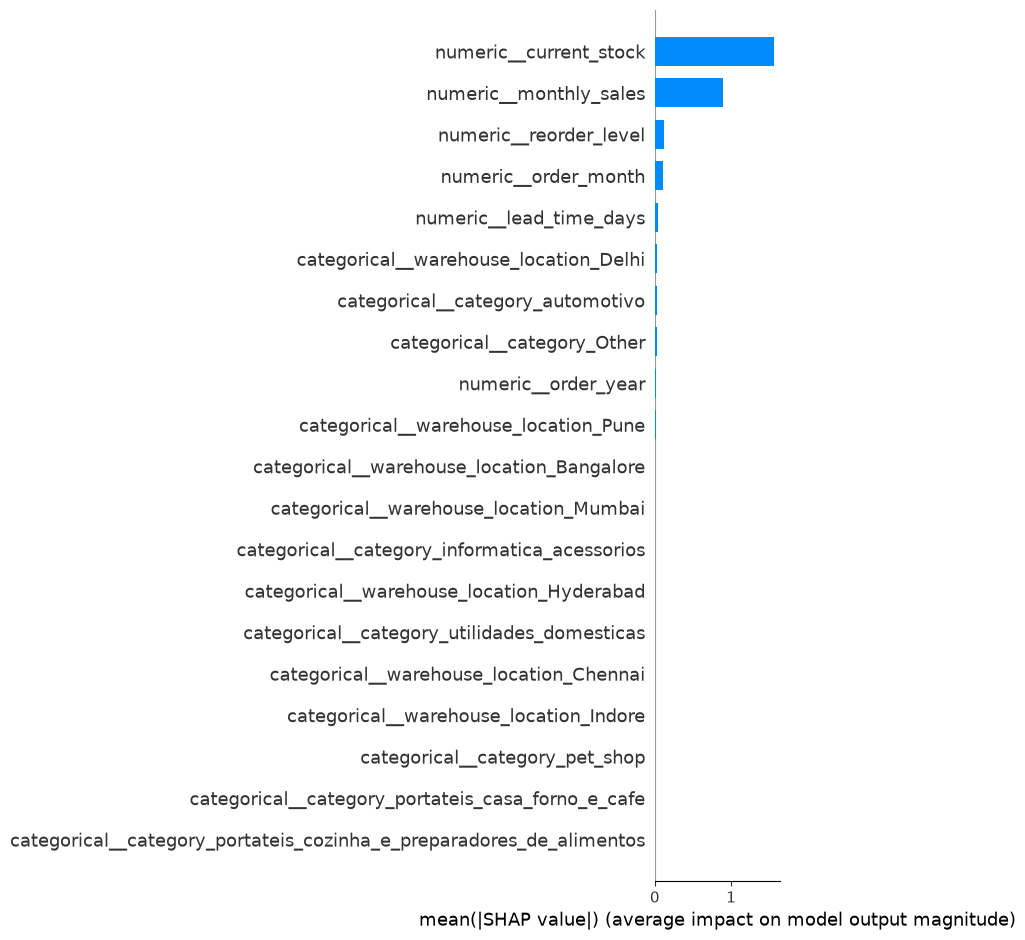

Updated SHAP plots saved for: HistGradientBoosting


In [28]:
import shap
import matplotlib.pyplot as plt
import numpy as np

shap_dir = models_dir / "shap"
shap_dir.mkdir(parents=True, exist_ok=True)

# Get the fitted preprocessing and selected model
preprocessor = best_model.named_steps["preprocessor"]
final_estimator = best_model.named_steps["model"]

# Create small background and explanation samples
X_background_raw = X_train.sample(
    n=min(50, len(X_train)),
    random_state=42
)

X_explain_raw = X_test.sample(
    n=min(80, len(X_test)),
    random_state=42
)

# Transform using the fitted preprocessing pipeline
X_background = preprocessor.transform(X_background_raw)
X_explain = preprocessor.transform(X_explain_raw)

feature_names = preprocessor.get_feature_names_out()

# Model-agnostic SHAP explanation
explainer = shap.Explainer(
    final_estimator.predict,
    X_background,
    feature_names=feature_names,
    algorithm="permutation"
)

shap_values = explainer(
    X_explain,
    max_evals=2 * X_explain.shape[1] + 1
)

# Summary plot
shap.summary_plot(
    shap_values.values,
    X_explain,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.savefig(
    shap_dir / "shap_summary.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Mean absolute SHAP feature importance
shap.summary_plot(
    shap_values.values,
    X_explain,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.savefig(
    shap_dir / "shap_feature_importance.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Updated SHAP plots saved for:", best_model_name)

In [29]:
from inventory_agent import inventory_agent

sample_inventory = {
    "order_year": 2018,
    "order_month": 5,
    "monthly_sales": 1,
    "current_stock": 10,
    "reorder_level": 4,
    "lead_time_days": 4,
    "category": "perfumaria",
    "warehouse_location": "Hyderabad"
}

for stock in [1, 10, 100]:
    test_input = sample_inventory.copy()
    test_input["current_stock"] = stock

    result = inventory_agent(test_input)

    print(f"\nCurrent stock: {stock}")
    print("Prediction:", result["prediction"])
    print("Recommendation:", result["recommended_action"])

ValueError: Missing inventory features: ['historical_sales', 'avg_daily_sales']

In [30]:
from inventory_agent import inventory_agent

sample_inventory = {
    "order_year": 2018,
    "order_month": 5,
    "monthly_sales": 1,
    "current_stock": 10,
    "reorder_level": 4,
    "lead_time_days": 4,
    "category": "perfumaria",
    "warehouse_location": "Hyderabad"
}

for stock in [1, 10, 100]:
    test_input = sample_inventory.copy()
    test_input["current_stock"] = stock

    result = inventory_agent(test_input)

    print(f"\nCurrent stock: {stock}")
    print("Prediction:", result["prediction"])
    print("Recommendation:", result["recommended_action"])

ValueError: Missing inventory features: ['historical_sales', 'avg_daily_sales']

In [31]:
from pathlib import Path
import joblib

models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

# Select the updated model trained with the new 8 features
best_model_name = "HistGradientBoosting"
best_model = trained_models[best_model_name]

# Define the current feature list
feature_columns = numeric_features + categorical_features

# Confirm the model was trained with these features
print("Model features:", list(best_model.feature_names_in_))
print("Current features:", feature_columns)

assert list(best_model.feature_names_in_) == feature_columns, (
    "The model and feature list do not match. "
    "Check the preprocessing and model-training cells."
)

# Save the updated model
joblib.dump(
    best_model,
    models_dir / "inventory_product_demand_model.pkl"
)

# Overwrite the old feature list
joblib.dump(
    feature_columns,
    models_dir / "inventory_features.pkl"
)

print("\nUpdated model and feature list saved successfully.")

Model features: ['order_year', 'order_month', 'monthly_sales', 'current_stock', 'reorder_level', 'lead_time_days', 'category', 'warehouse_location']
Current features: ['order_year', 'order_month', 'monthly_sales', 'current_stock', 'reorder_level', 'lead_time_days', 'category', 'warehouse_location']

Updated model and feature list saved successfully.


In [32]:
import importlib
import inventory_agent

# Reload the latest saved Python module
importlib.reload(inventory_agent)

sample_inventory = {
    "order_year": 2018,
    "order_month": 5,
    "monthly_sales": 1,
    "current_stock": 10,
    "reorder_level": 4,
    "lead_time_days": 4,
    "category": "perfumaria",
    "warehouse_location": "Hyderabad"
}

for stock in [1, 10, 100]:
    test_input = sample_inventory.copy()
    test_input["current_stock"] = stock

    result = inventory_agent.inventory_agent(test_input)

    print("\n" + "=" * 50)
    print("Current stock:", stock)
    print("Prediction:", result["prediction"])
    print("Recommendation:", result["recommended_action"])


Current stock: 1
Prediction: {'predicted_next_month_demand': 1.76, 'current_stock': 1.0, 'estimated_lead_time_demand': 0.23, 'reorder_point': 4.23, 'stock_risk': 'High', 'reorder_required': True, 'recommended_reorder_quantity': 5}
Recommendation: High stock risk. Consider replenishing 5 units to reach the estimated target stock level.

Current stock: 10
Prediction: {'predicted_next_month_demand': 1.76, 'current_stock': 10.0, 'estimated_lead_time_demand': 0.23, 'reorder_point': 4.23, 'stock_risk': 'Low', 'reorder_required': False, 'recommended_reorder_quantity': 0}
Recommendation: Current stock meets the estimated target stock level. Continue monitoring sales and inventory.

Current stock: 100
Prediction: {'predicted_next_month_demand': 7.1, 'current_stock': 100.0, 'estimated_lead_time_demand': 0.95, 'reorder_point': 4.95, 'stock_risk': 'Low', 'reorder_required': False, 'recommended_reorder_quantity': 0}
Recommendation: Current stock meets the estimated target stock level. Continue mon